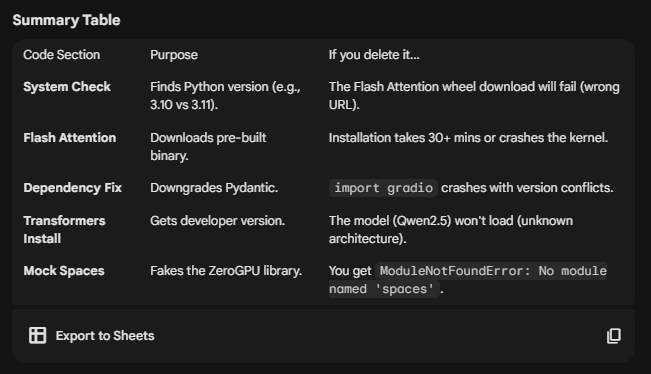

In [9]:
!apt-get install -y poppler-utils  # System dependency for PDF processing

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
poppler-utils is already the newest version (22.02.0-2ubuntu0.12).
0 upgraded, 0 newly installed, 0 to remove and 95 not upgraded.


In [10]:
import sys
import torch
import subprocess

print("System Check...")
py_ver_short = f"cp{sys.version_info.major}{sys.version_info.minor}" # e.g., 'cp310', 'cp311'
print(f"   Python: {sys.version.split()[0]} ({py_ver_short})")
print(f"   PyTorch: {torch.__version__}")

# --- 2. Fix Dependency Conflicts (The "Hell" Fix) ---
# Gradio 5+ needs Pydantic < 2.12, but other libs install 2.12. We force downgrade Pydantic first.
print("\nFixing Dependencies...")
subprocess.run("pip install \"pydantic<2.12\" --force-reinstall", shell=True)

# Now install the heavy hitters
# Qwen2.5-VL needs the absolute latest transformers (dev version)
# We install qwen-vl-utils and others *after* fixing pydantic
cmd_packages = (
    "pip install -q "
    "git+https://github.com/huggingface/transformers "
    "qwen-vl-utils "
    "gradio "
    "accelerate"
)
subprocess.run(cmd_packages, shell=True)

System Check...
   Python: 3.12.12 (cp312)
   PyTorch: 2.8.0+cu126

Fixing Dependencies...
  Using cached pydantic-2.11.10-py3-none-any.whl.metadata (68 kB)
  Using cached annotated_types-0.7.0-py3-none-any.whl.metadata (15 kB)
  Using cached pydantic_core-2.33.2-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (6.8 kB)
  Using cached typing_extensions-4.15.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached typing_inspection-0.4.2-py3-none-any.whl.metadata (2.6 kB)
Using cached pydantic-2.11.10-py3-none-any.whl (444 kB)
Using cached pydantic_core-2.33.2-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (2.0 MB)
Using cached annotated_types-0.7.0-py3-none-any.whl (13 kB)
Using cached typing_extensions-4.15.0-py3-none-any.whl (44 kB)
Using cached typing_inspection-0.4.2-py3-none-any.whl (14 kB)
  Attempting uninstall: typing-extensions
    Found existing installation: typing_extensions 4.15.0
    Uninstalling typing_extensions-4.15.0:
      Successfully unins

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.26.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
google-colab 1.0.0 requires jupyter-server==2.14.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.32.5 which is incompatible.
langchain 0.3.27 requires SQLAlchemy<3,>=1.4, but you have sqlalchemy 1.2.19 which is incompatible.
dopamine-rl 4.1.2 requires gymnasium>=1.0.0, but you have gymnasium 0.29.0 which is incompatible.
sentence-transformers 5.1.1 requires transformers<5.0.0,>=4.41.0, but you have transformers 5.3.0.dev0 which is incompatible.
cudf-cu12 25.6.0 requires pyarrow<20.0.0a0,>=14.0.0; platform_machine == "x86_64", but you have pyarrow 22.0.0 which is incompatible.
pydrive2 1.21.3 requires cryptography<44, but you have cryptogr

CompletedProcess(args='pip install -q git+https://github.com/huggingface/transformers qwen-vl-utils gradio accelerate', returncode=0)

### pdf2image is actually a wrapper around a command-line software suite called Poppler.

In [11]:
!pip install -q fastapi uvicorn python-multipart pyngrok pdf2image pillow bitsandbytes

In [12]:
# quantization_config = BitsAndBytesConfig(
#     # MASTER SWITCH: Turns on 4-bit quantization.
#     # What it does: Replaces Linear layers with 4-bit layers to save RAM.
#     load_in_4bit=True,

#     # MEMORY SAVER: "Quantize the quantization constants."
#     # What it does: Compresses the extra 32-bit constants needed for 4-bit math.
#     # Why use it: Saves ~0.5 bits per parameter (about 250MB - 3GB RAM) with zero cost to accuracy.
#     bnb_4bit_use_double_quant=True,

#     # STORAGE FORMAT: "NormalFloat 4" (The Smart Format).
#     # What it does: Stores weights in a distribution that matches the "Bell Curve" of neural networks.
#     # Why use it: It is mathematically more accurate than standard "fp4" for LLMs.
#     bnb_4bit_quant_type="nf4",

#     # COMPUTE PRECISION: The "Working Memory."
#     # What it does: De-quantizes the 4-bit weights into this format to do the actual math.
#     # Critical for Kaggle (T4): MUST be torch.float16. 
#     # (If you set this to 'bfloat16' on a T4, it will crash or crawl).
#     bnb_4bit_compute_dtype=torch.float16,

#     # SAFETY NET: "Don't touch these layers."
#     # What it does: Explicitly keeps these specific modules in full precision (FP16/32).
#     # Why use it: Essential for VLMs. If you compress the "Vision Tower" (eyes), the model goes blind.
#     llm_int8_skip_modules=vision_skip_layers
# )

The Token Limit (Truncation)
The Difference: 

Script 1 (Gradio): max_new_tokens=4096

Script 2 (FastAPI): max_new_tokens=1024

Why it hurts performance: Manga pages are incredibly dense. Outputting the transcribed text alongside the bounding box coordinates [xmin, ymin, xmax, ymax, ...] for every single speech bubble and sound effect consumes a massive amount of tokens. By capping it at 1024, the model is likely stopping mid-generation. It will look like the OCR simply "missed" the bottom half of the page.

Image Resizing Logic (Patch Misalignment)
The Difference:

Script 1 (Gradio): Uses Qwen's official smart_resize function.

Script 2 (FastAPI): Uses a custom mathematical ratio calculation.

Why it hurts performance: Vision-Language Models (VLMs) like Qwen2-VL don't look at images pixel-by-pixel; they slice the image into a grid of "patches" (e.g., 14x14 or 28x28 pixels).
The smart_resize function calculates the closest possible dimensions that are perfect multiples of the model's patch size.

In [13]:
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
NGROK_TOKEN = user_secrets.get_secret("NGROK_AUTH_TOKEN_ALT")
HF_TOKEN = user_secrets.get_secret("NGROK_AUTH_TOKEN_ALT")

In [1]:
%%writefile app.py
import os, re, io, torch, uvicorn, subprocess
from fastapi import FastAPI, UploadFile, File, Form, HTTPException
from fastapi.middleware.cors import CORSMiddleware
from pyngrok import ngrok
from io import BytesIO
from typing import List, Optional
from pdf2image import convert_from_bytes
from qwen_vl_utils import process_vision_info, smart_resize
from transformers import (
    Qwen2VLImageProcessor,
    Qwen2VLVideoProcessor,
    AutoTokenizer,
    Qwen2_5_VLProcessor,
    Qwen2_5_VLForConditionalGeneration,
    BitsAndBytesConfig
)
from collections import Counter
from PIL import Image, ImageOps
import base64
from kaggle_secrets import UserSecretsClient

# --- CONFIGURATION ---
REPO_ID = "hal-utokyo/MangaLMM"

PORT = 8000

NGROK_TOKEN = os.getenv("NGROK_TOKEN")
HF_TOKEN = os.getenv("HF_TOKEN")

if not NGROK_TOKEN or not HF_TOKEN:
    try:
        from kaggle_secrets import UserSecretsClient
        user_secrets = UserSecretsClient()
        if not NGROK_TOKEN:
            NGROK_TOKEN = user_secrets.get_secret("NGROK_AUTH_TOKEN_ALT")
        if not HF_TOKEN:
            # Note: Ensure the secret name in Kaggle is actually "HF_TOKEN"
            HF_TOKEN = user_secrets.get_secret("HF_TOKEN") 

    except Exception as e:
        print(f"Could not fetch secrets from Kaggle Client: {e}")
        # Manual Fallback (Replace these if running locally)
        if not NGROK_TOKEN: NGROK_TOKEN = "YOUR_MANUAL_NGROK_TOKEN"
        if not HF_TOKEN: HF_TOKEN = "YOUR_MANUAL_HF_TOKEN"

# --- MODEL LOADING ---
print(f"Configuring Model {REPO_ID}...")

vision_skip_layers = ["model.visual.merger.mlp.0", "model.visual.merger.mlp.2"]
for i in range(32):
    # list all of the layers loop
    vision_skip_layers.extend([
        f"model.visual.blocks.{i}.attn.qkv",
        f"model.visual.blocks.{i}.attn.proj",
        f"model.visual.blocks.{i}.mlp.gate_proj",
        f"model.visual.blocks.{i}.mlp.up_proj",
        f"model.visual.blocks.{i}.mlp.down_proj",
    ])

# First Pass: The model weights are quantized to 4-bit.
# This creates a large set of 32-bit scale constants.
# Second Pass: Those 32-bit constants are then quantized down to 8-bit.
quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_use_double_quant=True, # Compresses the extra 32-bit constants needed for 4-bit math to scale back to actual value (e.g. float16).
    bnb_4bit_quant_type="nf4", # Stores weights in a distribution that matches the "Bell Curve" of neural networks.
    bnb_4bit_compute_dtype=torch.float16, # De-quantizes the 4-bit weights into this format to do the actual math.
    llm_int8_skip_modules=vision_skip_layers # Explicitly keeps these specific modules in full precision (FP16/32).
)


# Vision-Language Models need specific tools to translate different types of data
# (pixels vs. text) into numbers (tensors/tokens) that the neural network can understand.

# Loads the pre-trained configuration to handle images. It manages resizing, normalizing, and converting images into the patch format Qwen expects.
image_processor = Qwen2VLImageProcessor.from_pretrained(REPO_ID)

# Converts your plain text prompts into discrete numeric "tokens" that the language model understands.
tokenizer = AutoTokenizer.from_pretrained(REPO_ID)

# Handles video inputs. Notice **image_processor.to_dict(): it copies the configuration from the image processor
# (like resolution or normalization stats) to process video frames consistently.
video_processor = Qwen2VLVideoProcessor(**image_processor.to_dict())

# Wraps the image, video, and text processors into one unified object.
# Later, when you pass a prompt with text and an image, this master processor routes the data to the correct sub-processor automatically.
processor = Qwen2_5_VLProcessor(
    image_processor=image_processor,
    video_processor=video_processor,
    tokenizer=tokenizer
)

# Chat Template
qwen_chat_template = (
    "{% set image_count = namespace(value=0) %}"
    "{% set video_count = namespace(value=0) %}"
    "{% for message in messages %}"
        "{% if loop.first and messages[0]['role'] != 'system' %}"
            "<|im_start|>system\nYou are a helpful assistant.<|im_end|>\n"
        "{% endif %}"
        "<|im_start|>{{ message['role'] }}\n"
        "{% if message['content'] is string %}"
            "{{ message['content'] }}"
        "{% else %}"
            "{% for content in message['content'] %}"
                "{% if content['type'] == 'image' %}"
                    "<|vision_start|><|image_pad|><|vision_end|>"
                "{% elif content['type'] == 'video' %}"
                    "<|vision_start|><|video_pad|><|vision_end|>"
                "{% elif content['type'] == 'text' %}"
                    "{{ content['text'] }}"
                "{% endif %}"
            "{% endfor %}"
        "{% endif %}"
        "<|im_end|>\n"
    "{% endfor %}"
    "{% if add_generation_prompt %}"
    "<|im_start|>assistant\n"
    "{% endif %}"
)

# This simply attaches the Jinja2 template you just defined to your processors.
# Now, when you call processor.apply_chat_template(messages),
# it will use your custom formatting rules rather than the default ones.
processor.tokenizer.chat_template = qwen_chat_template
processor.chat_template = qwen_chat_template

print("Loading Model...")

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    REPO_ID,
    torch_dtype=torch.float16,
    quantization_config=quantization_config,
    device_map="auto",
    token=HF_TOKEN
)

# --- TEXT PROCESSING FUNCTIONS ---
def pil2base64(image: Image.Image) -> str:
    # Image to base64 so it can safely travel across text-based systems.
    # If you try to paste raw binary data directly into a JSON payload to send over the internet,
    # it will break the formatting and corrupt the data.
    buffered = BytesIO()
    image.save(buffered, format="PNG")
    return base64.b64encode(buffered.getvalue()).decode()

def bbox2d_to_quad(bbox_2d):
    
    xmin, ymin, xmax, ymax = bbox_2d
    # xmin + ymin = top-left
    # xmax + ymin = top-right
    # xmax + ymax = bottom-right
    # xmin + ymax = bottom-left
    return [xmin, ymin, xmax, ymin, xmax, ymax, xmin, ymax] 

def normalize_repeated_symbols(text):
    """Fixes weird stuttering like ~~~~ becoming ~."""

    text = re.sub(r'([~\～\〜\-\ー]+)', lambda m: m.group(1)[0], text)
    text = re.sub(r'[~～〜]', '~', text)
    text = re.sub(r'[-ー]', '-', text)
    
    return text

def normalize_punctuation(text):
    """Converts Japanese punctuation (like full-width ！)
    to standard English versions (!) for consistency."""
    
    conversion_map = {
        "！": "!", "？": "?", "…": "..."
    }
    pattern = "|".join(map(re.escape, conversion_map.keys()))
    text = re.sub(pattern, lambda m: conversion_map[m.group()], text)
    text = re.sub(r'[・･.]', '・', text)

    return text


def restore_chouon(text):
    """Crucial for Japanese: The model sometimes confuses the long vowel mark ー with a hyphen -.
    This function uses regex to check if the hyphen is between Japanese characters;
    if so, it turns it back into ー."""

    # Extended Unicode version: covers Hiragana, Katakana, and Kanji (including Extension A)
    jp_range = r"\u3040-\u309F\u30A0-\u30FF\u3400-\u4DBF\u4E00-\u9FFF"
    pattern = rf"(?<=[{jp_range}])-(?=[{jp_range}])"

    return re.sub(pattern, "ー", text)

def process_text(text: str) -> str:
    # Remove all whitespaces

    # OCR models often insert random spaces or newlines between every single character (e.g., H e l l o).
    text = re.sub(r"[\s\u3000]+", "", text)
    text = normalize_repeated_symbols(text)
    text = normalize_punctuation(text)
    text = restore_chouon(text)
    
    return text

def parse_ocr_text(text: str) -> list[dict]:
    if not text.strip(): return []
    # Handle escaped quotes
    text = text.replace('\\"', '"')

    # Finds blocks of text that look like structured data { ... }
    blocks = re.findall(r"\{[^{}]*?\"bbox_2d\"[^{}]*?\"text_content\"[^{}]*?\}", text, re.DOTALL)
    # Also handle reversed key order:
    blocks += re.findall(r"\{[^{}]*?\"text_content\"[^{}]*?\"bbox_2d\"[^{}]*?\}", text, re.DOTALL)
    ocrs = []

    for block in blocks:
        block = block.strip()

        # Inside each block, it looks for "bbox_2d": [...] and "text_content": "...".
        bbox_match = re.search(r'"bbox_2d"\s*:\s*\[([^\]]+)\]', block, flags=re.DOTALL)
        text_match = re.search(r'"text_content"\s*:\s*"([^"]*)"', block, flags=re.DOTALL)

        if bbox_match and text_match:
            try:
                # Context: bbox_match.group(1) returns a string like "105, 204, 500, 600".
                # .split(","): Breaks that string into a list of strings: ['105', ' 204', ' 500', ' 600'].
                # x.strip(): Removes extra whitespace (like the space before 204).
                # int(...): Converts the string '105' into the number 105.
                # Result: You get a clean list of integers: [105, 204, 500, 600].
                # These represent [xmin, ymin, xmax, ymax].
                bbox_list = [int(x.strip()) for x in bbox_match.group(1).split(",")]

                content = process_text(text_match.group(1)) # Returns a clean string like "Hello" from "H e l l o".
                
                # Context: Most drawing libraries (and advanced OCR formats)
                # prefer defining a box by 4 points (8 numbers) rather than just 2 points (4 numbers).
                # 2-Point Format (BBox): [xmin, ymin, xmax, ymax] (Top-Left, Bottom-Right).
                # 4-Point Format (Quad): [x1, y1, x2, y2, x3, y3, x4, y4]
                # (Top-Left, Top-Right, Bottom-Right, Bottom-Left).
                quad = bbox2d_to_quad(bbox_list)
                # Store tuple for deduplication: (text, xmin, ymin, xmax, ymax...)
                ocrs.append((content, bbox_list, quad)) 
            except:
                continue

    # Remove duplicates (sometimes the model generates the same text multiple times)
    # Logic: If exact same text appears more than 10 times, it's likely a hallucination loop
    # Counter looks at that massive list and counts how many times identical text appears across the whole page.
    text_counter = Counter([o[0] for o in ocrs])
    final_results = []

    for content, bbox, quad in ocrs:
        if text_counter[content] < 10:
            final_results.append({
                "text": content,
                "bbox_2d": bbox,
                "quad": quad
            })

    return final_results

# --- INFERENCE LOGIC ---
def run_inference(image: Image.Image, prompt: str = None):

    # Store original height for scale back
    orig_width, orig_height = image.width, image.height

    # Max pixel (4k)
    max_pixels = 2116800
    if image.width * image.height > max_pixels:

        # Use qwen smart_resize to get the height and width that is fitting for the reading of VLM which read in patch of 14x14 or 16x16 
        resized_height, resized_width = smart_resize(
            height=image.height,
            width=image.width,
            factor=processor.image_processor.patch_size * processor.image_processor.merge_size,
            min_pixels=processor.image_processor.min_pixels,
            max_pixels=processor.image_processor.max_pixels,
        )

        # Resize using the preferred height and width
        # Bicubic is the best balance between preserving high-quality image details and computational speed
        image = image.resize((resized_width, resized_height), resample=Image.Resampling.BICUBIC)

    # OCR (Main Purpose)
    if not prompt:
        prompt = "Please perform OCR on this image and output the recognized Japanese text along with its position (grounding)."

    # Convert to base64 to match what gradio do
    base64_image = pil2base64(image)

    messages = [
        {"role": "user", "content": [
            {"type": "image", "image": f"data:image;base64,{base64_image}"},
            {"type": "text", "text": prompt},
        ]},
    ]

    text_input = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    
    # extract and prepare the actual image
    # Qwen2_5_VLProcessor cannot read a string like "path/to/my_photo.jpg" or a base64 string directly
    # Automated media fetcher, see the type of file, the location (local/url/base64), and convert to PIL image
    # Outputting: It returns two neat lists: image_inputs (a list of all the PIL Images found in the prompt) and video_inputs (a list of all the processed video data).
    image_inputs, video_inputs = process_vision_info(messages)

    # This takes your formatted text prompt, your extracted PIL images, and your videos, and turns everything into numbers (tokens for text, pixel values for images).
    inputs = processor(
        text=[text_input], 
        images=image_inputs, 
        videos=video_inputs, 
        padding=True, # If you were passing multiple prompts at once (a batch), this makes sure all the mathematical arrays are padded with zeros so they are exactly the same length.
        return_tensors="pt"
    ).to("cuda") # It physically moves these data matrices from your computer's standard RAM (CPU) over to the incredibly fast memory (VRAM) of your NVIDIA GPU (cuda).

    # This is where the actual AI inference happens.
    # **inputs: Unpacks your dictionary of PyTorch tensors and feeds them into the model.
    # generated_ids: The output is a long list of numbers (token IDs), not text.
    generated_ids = model.generate(**inputs, max_new_tokens=4096)

    # When Hugging Face models generate text, they actually output the entire conversation history (your prompt) plus the new answer appended to the end.
    # This line uses a Python list comprehension to slice the array. It calculates the length of your input (len(in_ids)) and chops off that many tokens from the beginning of the output.
    generated_ids_trimmed = [out_ids[len(in_ids):] for in_ids, out_ids in zip(inputs.input_ids, generated_ids)]

    # turn those raw numbers back into a readable string.
    # batch_decode(...): Reverses the tokenizer's job, mapping numbers back to words.
    # skip_special_tokens=True: Strips out the invisible control tags (like <|im_end|> or <|im_start|>) so you just get a clean, human-readable response.
    # clean_up_tokenization_spaces=False: This is very important for OCR (Optical Character Recognition). Tokenizers sometimes add or remove spaces randomly during decoding.
    # Setting this to False forces the decoder to leave the exact spacing the model intended.
    # [0]: Plucks the first (and likely only) response out of the batch list.
    raw_output = processor.batch_decode(generated_ids_trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False)[0]
    
    # print(raw_output)
    # Get only the ocr result
    ocr_blocks = parse_ocr_text(raw_output)
    
    # SCALE COORDINATES BACK TO ORIGINAL SIZE FOR CORRECT BBOX PLACEMENT
    if orig_width != image.width or orig_height != image.height:
        
        # Get the scale of the original compare to current
        scale_w = orig_width / image.width
        scale_h = orig_height / image.height
        
        for block in ocr_blocks:
            box = block["bbox_2d"]
            # Scale [xmin, ymin, xmax, ymax]
            scaled_box = [
                int(box[0] * scale_w),
                int(box[1] * scale_h),
                int(box[2] * scale_w),
                int(box[3] * scale_h)
            ]
            block["bbox_2d"] = scaled_box
            block["quad"] = bbox2d_to_quad(scaled_box)
            
    return {
        "raw_text": raw_output, 
        "ocr_blocks": ocr_blocks
    }
    
# --- FASTAPI APP ---
app = FastAPI()
app.add_middleware(CORSMiddleware, allow_origins=["*"], allow_credentials=True, allow_methods=["*"], allow_headers=["*"])


@app.post("/predict")
# async def: Makes the function asynchronous, allowing the server to handle other requests while waiting for the model to finish generating text.
# By using request: TranslationRequest in the function signature, FastAPI (and Pydantic) enforces that the incoming JSON must have a specific key—likely japanese_text
async def predict_endpoint(file: UploadFile = File(...), prompt: Optional[str] = Form(None)):

    # Reading the File into Memory
    file_bytes = await file.read()
    filename = file.filename.lower()
    results = []

    try:
        if filename.endswith(".pdf"):

            # turn a multi-page PDF document into a list of standard PIL Images (one image per page).
            images = convert_from_bytes(file_bytes)
            
            for i, img in enumerate(images):
                results.append({"page": i+1, "data": run_inference(img, prompt)})

        else:
            
            # BytesIO(file_bytes): Tricks Python into treating your raw RAM bytes like a physical file.
            img = Image.open(BytesIO(file_bytes)).convert("RGB")
            results.append({"page": 1, "data": run_inference(img, prompt)})

        return {"status": "success", "results": results}

    except Exception as e:
        raise HTTPException(status_code=500, detail=str(e))

if __name__ == "__main__":
    # 2. Kill old tunnels (just in case)
    ngrok.kill()

    # 3. Connect to the running server (Port 8000)
    if NGROK_TOKEN:
        ngrok.set_auth_token(NGROK_TOKEN)
        try:
            public_url = ngrok.connect(8000)
            print("="*50)
            print(f"NGROK URL: {public_url.public_url}")
            print("="*50)
            
        except Exception as e:
            print(f"Ngrok Connection Failed: {e}")
            
    else:
        print("Error: No NGROK_TOKEN found. Please paste it directly in the code above.")
    uvicorn.run(app, host="0.0.0.0", port=PORT)

Writing app.py


In [2]:
# Pass your secrets as environment variables directly in the command
!python app.py

Traceback (most recent call last):
  File "/kaggle/working/app.py", line 4, in <module>
    from pyngrok import ngrok
ModuleNotFoundError: No module named 'pyngrok'
^C


In [ ]:
# # Kill the specific process ID
# try:
#     process.terminate()
#     process.wait()
#     print("✅ Server stopped.")
# except:
#     print("⚠️ Server process not found or already stopped.")
    
# # Force kill python if stuck (nuclear option)
# !pkill -f app.py